Environment set up and importing libraries



In [1]:
# WHY: Colab environments do not always ship with yfinance, so I installed everything
# the notebook needs in one place. '-q' keeps the output quiet so the notebook stays readable.
# Library roles: yfinance = price download, pandas/numpy = tables & maths, scipy/scikit-learn = clustering,
# scaling, PCA and validation metrics | matplotlib/seaborn = charts.

# Install and import required libraries
!pip install yfinance scikit-learn seaborn matplotlib pandas numpy scipy -q

In [2]:
# WHY: All imports are grouped in the first code cell so dependencies are visible at a glance
# and any import problem fails immediately, before a slow data download starts.

import os
import datetime
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


1.1 Ticker extraction and data download

In [3]:
# WHY: The S&P 500 membership changes over time, so I scraped the current constituent list from Wikipedia
# and record the retrieval date. That date is the audit trail so anyone repeating the study later can see
# which version of the index list was used.

# 1.1 Ticker Extraction from Wikipedia
retrieval_date = datetime.date.today().isoformat()
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Wikipedia can reject requests that use pandas default user agent (HTTP 403), so we send a browser-like
# User-Agent header. It is only an identification string and it does not change the data returned.
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

print(f"Extracting S&P 500 constituents from Wikipedia on: {retrieval_date}")
# read_html returns every HTML table on the page as a list of DataFrames.
tables = pd.read_html(url, storage_options=headers)

# tables[0] is the current constituents table (the second table is historical changes).
# We keep only the columns I need which are: ticker, company name and GICS sector/sub-industry. The sector will be
# joined back to the features at the end so clusters can be interpreted by industry.
# .copy() avoids pandas' Setting with copy warning when we add a column in the next cell.

sp500_meta = tables[0][['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry']].copy()

Extracting S&P 500 constituents from Wikipedia on: 2026-11-18


In [4]:
# WHY: Wikipedia writes share classes with a dot (BRK.B, BF.B) but Yahoo Finance uses a dash (BRK-B).
# Without this fix those tickers would fail to download.

# Adjust ticker symbols for Yahoo Finance (e.g. BRK.B -> BRK-B)
# regex=False is deliberate: in a regular expression '.' means 'any character', which would wipe out
# every character in the ticker. With regex=False it is treated as a full stop.

sp500_meta['Ticker'] = sp500_meta['Symbol'].str.replace('.', '-', regex=False)

# Convert to a plain list because yfinance expects a list of symbols.
tickers = sp500_meta['Ticker'].tolist()
print(f"Total constituents extracted: {len(tickers)}")

Total constituents extracted: 503


In [5]:
# Ensure raw_data is defined before running the duplicate index check
if 'raw_data' in globals():
    duplicate_count = raw_data.index.duplicated().sum()
    print(f"Number of duplicated index entries: {duplicate_count}")
else:
    print("raw_data is not yet downloaded. Please run the download cell (cell I7BqOxtMLHBQ) first.")

raw_data is not yet downloaded. Please run the download cell (cell I7BqOxtMLHBQ) first.


In [6]:
# WHY: One bulk download is much faster than looping over 500 tickers, and gives every share on the
# same date index, which makes later alignment with the benchmark simple.

# 1.1 Download Daily Historical Prices (2021-01-01 to 2025-01-01 exclusive)
# Study window: 1 Jan 2021 to 31 Dec 2024. yfinance treats 'end' as EXCLUSIVE, so end='2025-01-01'
# means the last day downloaded is 31 Dec 2024. That gives four full calendar years (~1,005 sessions).
start_date = '2021-01-01'
end_date = '2025-01-01'
# ^GSPC (S&P 500 index) is added because it is the market benchmark required to estimate beta.
all_symbols = tickers + ['^GSPC']

print(f"Downloading daily market data for {len(all_symbols)} symbols...")
# auto_adjust=False preserves both raw Close and dividend/split Adjusted Close
# auto_adjust=False is the key decision: it keeps BOTH the raw 'Close' and the 'Adj Close'.
#   - Adj Close (dividend/split adjusted) is used for RETURNS and BETA, because returns should reflect
#     what an investor really earned.
#   - Raw Close is used for the MONETARY value (Close x Volume), because actual traded money was
#     paid at the raw price, and volume is quoted in raw shares.
# group_by='column' makes the result indexed as raw_data['Adj Close'][ticker], a layout used throughout.
# Note: the 5 failed tickers in the output (SNDK, HONA, FDXF, VYLR, Q) did not trade in this window
# (recent listings/renames); they come back as empty columns and are removed by the completeness check later.
raw_data = yf.download(all_symbols, start=start_date, end=end_date, auto_adjust=False, group_by='column')

# Save local pickle snapshot for reproducibility & offline caching
# Cache the download to disk so the study can be re-run offline and Yahoo's later restatements
# (adjusted prices change when new dividends occur) cannot change the results.
raw_data.to_pickle("sp500_raw_market_data.pkl")
print(f"Download complete. Preserved snapshot shape: {raw_data.shape}")

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'HONA', 'Q', 'FDXF', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Download complete. Preserved snapshot shape: (1005, 3024)


1.2 Data validation

In [7]:
# WHY: Before computing anything we need (a) a reference trading calendar and (b) a list to record
# every share we remove and why. Logging exclusions is good practice: the final sample is transparent
# and the report can state exactly how many shares were dropped at each stage.

exclusion_log = []

# Benchmark reference dates
# The S&P 500 index trades on every US session, so its non-missing dates act as the 'true' trading calendar.
# We compare each share against this count (1,005 sessions) to detect missing data.
benchmark_adj = raw_data['Adj Close']['^GSPC'].dropna()
total_trading_days = len(benchmark_adj)
print(f"Benchmark (^GSPC) total valid trading sessions: {total_trading_days}")

# Defensive checks on the ticker list itself: duplicates would double-count a share in clustering.
# Pre-check 1: Duplicate tickers
dup_tickers = [t for t in tickers if tickers.count(t) > 1]
if dup_tickers:
    print(f"WARNING: Duplicate tickers detected and deduplicated: {set(dup_tickers)}")
# dict.fromkeys removes duplicates while PRESERVING order (a set() would scramble the order).
tickers = list(dict.fromkeys(tickers))  # Remove duplicates, preserve order

# Any ticker still containing '.' means the replacement in the earlier cell missed something;
# we only warn here, we do not remove, because none were found.
# Pre-check 2: Ticker format (dot notation = Yahoo Finance will fail)
bad_format = [t for t in tickers if '.' in t]
if bad_format:
    print(f"WARNING: Dot-notation tickers found (should be '-'): {bad_format}")

Benchmark (^GSPC) total valid trading sessions: 1005


In [8]:
# WHY: Each share passes through seven data-quality gates. 'continue' stops at the FIRST failure, so every
# excluded share has exactly one logged reason. Gates are ordered from the most basic problem (not enough data)
# to the most subtle (stale prices), so cheaper/more fundamental checks run first.
# Only shares that pass every gate are appended to valid_tickers (the clean sample used from here on).


valid_tickers = []

for ticker in tickers:
    try:
        # Pull raw Close, Adj Close and Volume for this share. Both price series are needed because errors can
        # show up in one but not the other.
        close_s  = raw_data['Close'][ticker]
        adj_s    = raw_data['Adj Close'][ticker]
        vol_s    = raw_data['Volume'][ticker]

        # CHECK 1 - Completeness (>= 98% of benchmark sessions).
        # Why: beta and RFM need a consistent history. Recent IPOs/spin-offs (e.g. APP, COIN, CEG) have no data for
        # part of the window, so their returns are not comparable. 98% tolerates a few genuine data gaps (outages)
        # but rejects shares with materially short histories.
        # CHECK 1: Completeness — require >= 98% of benchmark trading days
        valid_days = adj_s.dropna().shape[0]
        if valid_days < (total_trading_days * 0.98):
            exclusion_log.append({
                'Ticker': ticker,
                'Reason': f'Incomplete history: {valid_days}/{total_trading_days} sessions'
            })
            continue

        # CHECK 2 - Non-positive prices.
        # Why: a price can never be zero or negative; it signals corrupt data. Zero would also break percentage
        # returns (divide by zero) and log transforms later.
        # CHECK 2: Non-positive prices
        if (adj_s <= 0).any() or (close_s <= 0).any():
            exclusion_log.append({'Ticker': ticker, 'Reason': 'Non-positive prices encountered'})
            continue

        # CHECK 3 - Negative volume.
        # Why: volume is a count of shares traded, so a negative value is impossible and means a data error.
        # CHECK 3: Negative volume
        if (vol_s < 0).any():
            exclusion_log.append({'Ticker': ticker, 'Reason': 'Negative volume records encountered'})
            continue
        # CHECK 4 - Excess zero-volume days (> 2% of sessions).
        # Why: the Frequency measure counts unusually HIGH-volume days relative to a rolling average. A share with
        # many zero-volume days has an artificially low baseline, which would distort the high-volume flag.
        # It also indicates illiquid or halted trading, i.e. not a normal large-cap share.
        # CHECK 4: Zero-volume days (> 2% of trading sessions = suspicious)
        # Shares with many zero-volume days have artificially low Frequency (F)
        # Count of sessions with exactly zero volume, divided by total benchmark sessions to get a percentage.
        zero_vol_count = (vol_s == 0).sum()
        zero_vol_pct   = zero_vol_count / total_trading_days
        if zero_vol_pct > 0.02:
            exclusion_log.append({
                'Ticker': ticker,
                'Reason': f'Excess zero-volume days: {zero_vol_count} ({zero_vol_pct*100:.1f}%)'
            })
            continue
        # CHECK 5 - Extreme daily returns (|return| > 40%).
        # Why: a genuine one-day move of 40%+ is very rare for S&P 500 members; far more often it is an unadjusted
        # stock split or a bad data point. Left in, one fake -50% / +60% day would massively inflate volatility
        # and distort beta and the weekly returns. Removing such shares is safer than trying to repair them.
        # CHECK 5: Extreme daily returns — flag splits / data errors
        # An unadjusted stock split appears as a sudden -50% or -90% move.
        # Adj Close should handle this, but data errors still occur.
        # Threshold: ±40% single-day move on Adj Close is flagged.
        # dropna() first so that a missing day is skipped rather than creating a NaN; fill_method=None stops pandas
        # forward-filling a gap, which would otherwise fabricate a 0% day.
        daily_returns = adj_s.dropna().pct_change(fill_method=None)
        extreme_moves = (daily_returns.abs() > 0.40).sum()
        if extreme_moves > 0:
            # Record the largest move in the log so the exclusion can be justified in the report.
            max_move = daily_returns.abs().max()
            exclusion_log.append({
                'Ticker': ticker,
                'Reason': f'Extreme daily move detected: {extreme_moves} day(s) with |return| > 40% '
                          f'(max: {max_move*100:.1f}%). Possible unadjusted split or data error.'
            })
            continue

        # CHECK 6 - Stale prices (10+ identical consecutive closes).
        # Why: a real, liquid share almost never closes at exactly the same price for two weeks. A flat run means
        # the data feed stopped updating, which would produce false zero returns.
        # CHECK 6: Stale prices — long runs of identical closing price
        # 10+ consecutive identical Adj Close values = data stopped updating
        # diff() gives the day-to-day change; fillna(1) gives the first row a non-zero value so day 1
        # (which has no previous day) is not mistaken for a 'no change' day.
        price_changes   = adj_s.dropna().diff().fillna(1)      # fillna(1) avoids flagging day 1
        # True on days where the price did not change.
        unchanged       = (price_changes == 0)
        # Trick to measure the longest run of consecutive True values:
        #   1) (unchanged != unchanged.shift()).cumsum() gives each run of identical values its own group number;
        #   2) groupby(...).cumsum() counts 1,2,3... within each group (so True runs count up, False runs add 0);
        #   3) .max() is the longest consecutive 'unchanged' streak.
        max_streak      = unchanged.groupby((unchanged != unchanged.shift()).cumsum()).cumsum().max()
        if max_streak >= 10:
            exclusion_log.append({
                'Ticker': ticker,
                'Reason': f'Stale price detected: {int(max_streak)} consecutive identical closing prices'
            })
            continue

        # CHECK 7 - Remaining gaps (up to 2% missing days) are DROPPED, not forward-filled.
        # Why: forward-filling copies yesterday's price into the gap and creates artificial 0% return days that
        # dilute average returns and understate volatility/beta. Dropping the row keeps only real observations.
        # This is an information message only; nothing is removed here because the share is within the tolerance.
        # CHECK 7: Gap handling for the remaining up to 2% missing days
        # We DROP the missing rows entirely (do NOT forward-fill).
        # Rationale: forward-filling prices creates artificial zero-return
        # days that dilute weekly return estimates and distort beta.
        # Missing days are documented here. Returns are computed on
        # actual trading days only (pct_change on the aligned series).
        missing_days = adj_s.isna().sum()
        if missing_days > 0:
            print(f"  [INFO] {ticker}: {missing_days} missing day(s) — rows dropped (not filled).")
            # No exclusion — within the 2% tolerance. Rows are dropped
            # automatically when we call .dropna() in later computations.

        valid_tickers.append(ticker)

    # Safety net: if a ticker column is missing/corrupt (e.g. the 5 failed downloads), log it instead of
    # crashing the whole loop so the other 500 shares are still processed.
    except Exception as e:
        exclusion_log.append({'Ticker': ticker, 'Reason': f'Extraction failure: {str(e)}'})

In [9]:
# WHY: Turn the exclusion log into a DataFrame, save it as a CSV (evidence for the report) and print a
# summary so the sample size at each stage is explicit: 503 examined -> 481 retained.


# Save full exclusion log
# The CSV is later re-saved after the beta and RFM stages, so it becomes a complete record of every exclusion.
exclusion_df = pd.DataFrame(exclusion_log)
exclusion_df.to_csv("exclusion_log.csv", index=False)

# Summary report
print(f"\n{'='*55}")
print(f"DATA VALIDATION SUMMARY")
print(f"{'='*55}")
print(f"  Total tickers examined:  {len(tickers)}")
print(f"  Retained valid shares:   {len(valid_tickers)}")
print(f"  Excluded shares:         {len(exclusion_df)}")
if len(exclusion_df) > 0:
    print(f"\n  Exclusion Breakdown:")
    # Counts exclusions per category by matching the start of the reason text. The prefixes must match the
    # wording used in the checks above (a typo here would silently show 0 for that category).
    for reason_prefix in ['Incomplete', 'Non-positive', 'Negative vol',
                          'Excess zero', 'Extreme daily', 'Stale price', 'Extraction']:
        count = exclusion_df['Reason'].str.startswith(reason_prefix).sum()
        if count > 0:
            print(f"    - {reason_prefix}...: {count} shares")
print(f"{'='*55}")

print("\nSample exclusions:")
# display() is a Jupyter function (not plain Python); it renders the table nicely.
display(exclusion_df.head(8))


DATA VALIDATION SUMMARY
  Total tickers examined:  503
  Retained valid shares:   482
  Excluded shares:         21

  Exclusion Breakdown:
    - Incomplete...: 15 shares
    - Excess zero...: 2 shares
    - Extreme daily...: 4 shares

Sample exclusions:


,Ticker,Reason
0,APP,Incomplete history: 935/1005 sessions
1,BE,Extreme daily move detected: 1 day(s) with |re...
2,CVNA,Extreme daily move detected: 5 day(s) with |re...
3,COIN,Incomplete history: 936/1005 sessions
4,CEG,Incomplete history: 742/1005 sessions
5,DXCM,Extreme daily move detected: 1 day(s) with |re...
6,EXE,Incomplete history: 979/1005 sessions
7,FDXF,Incomplete history: 0/1005 sessions


1.3 Weekly return and beta estimation - weekly

In [10]:
# WHY WEEKLY: Daily returns are noisy and affected by non-synchronous trading and one-off events. Weekly
# returns smooth this noise while still giving ~200 observations, enough for a stable beta estimate.

# 1.3.1 Resample to Friday-ending weeks
# Use ADJUSTED close so dividends and splits do not appear as price drops. Only the validated shares plus
# the benchmark are kept, so excluded shares can never leak into later steps.
adj_close_selected = raw_data['Adj Close'][valid_tickers + ['^GSPC']]

# 'W-FRI' = weeks ending on Friday. .last() takes the last AVAILABLE price in each week, so if Friday is a
# market holiday (e.g. Good Friday) Thursday's close is used automatically. Using .mean() or .first() would
# be wrong because the return should reflect the end-of-week price.
weekly_prices = adj_close_selected.resample('W-FRI').last()

# Drop the final row if data ends early in the week (Mon-Wed).
# When the market closes on a Friday (e.g. Good Friday), the last trading
# day is Thursday — last_close_date < last_week_date would be true even
# for a complete week, so we check weekday() instead.
# Find the real final trading date in the data (not the Friday label that resample creates).
last_close_date = adj_close_selected.dropna(how='all').index[-1]

# weekday(): Monday=0 ... Friday=4. If the data ends Mon-Wed the final week is genuinely incomplete and would
# give a misleading 'weekly' return, so it is dropped. A Thursday/Friday end is consistent with a full (or
# holiday-shortened) week and is kept. Here data ends Tue 31 Dec 2024, so the last row is removed, leaving 207 weeks.
if last_close_date.weekday() < 3:   # 0=Mon, 1=Tue, 2=Wed → genuinely partial
    print(f"[INFO] Partial final week detected — data ends {last_close_date.date()} "
          f"({last_close_date.day_name()}). Dropping last weekly row.")
    weekly_prices = weekly_prices.iloc[:-1]
else:
    print(f"[INFO] Final week is complete — data ends {last_close_date.date()} "
          f"({last_close_date.day_name()}). No row dropped.")

[INFO] Partial final week detected — data ends 2024-12-31 (Tuesday). Dropping last weekly row.


In [11]:
# WHY: Beta measures how strongly a share moves with the market: beta = Covariance(share, market) / Variance(market).
# It is estimated from weekly returns, share by share, using only weeks where both the share and the
# market have a valid return.

# Compute weekly percentage returns.
# fill_method=None prevents silent forward-filling of missing prices.
# pct_change = (this week / last week) - 1. fill_method=None means a week with no price gives NaN (unknown),
# NOT a fake 0% return. iloc[1:] removes the first row, which is always NaN (no previous week).
weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]

# The market (^GSPC) return series, used as the common x-variable for every beta regression.
market_weekly_returns = weekly_returns['^GSPC'].dropna()
print(f"Total complete weekly periods used: {len(market_weekly_returns)}")

# 1.3.2 Weekly Beta Estimation
# Two lists: successful results and a log of shares that fail at this stage.
results_rr    = []
rr_exclusions = []

for ticker in valid_tickers:
    try:
        # dropna() removes weeks without a valid share return.
        share_ret = weekly_returns[ticker].dropna()

        # Align share and market returns on identical weekly timestamps
        # Align share and market on identical weeks (inner match on date) and drop any week missing either value.
        # Beta must be computed on the SAME weeks for numerator and denominator, otherwise it is biased.
        paired = pd.concat(
            [share_ret.rename('share'), market_weekly_returns.rename('market')],
            axis=1
        ).dropna()

        n_paired = len(paired)

        # Minimum 52 paired weeks (one year of data). With fewer observations beta is too unreliable to estimate.
        if n_paired >= 52:
            # Compute variance over the same paired weeks as the covariance,
            # so both statistics are computed on identical observations.
            # ddof=1 = sample variance (divide by n-1), the standard unbiased estimator. pandas .cov() also uses n-1,
            # so numerator and denominator use consistent definitions. The result equals the slope of an OLS regression of
            # share returns on market returns.
            paired_market_var = paired['market'].var(ddof=1)

            # Guard against dividing by zero (only possible with a constant market series; defensive coding).
            if paired_market_var > 0:
                cov      = paired['share'].cov(paired['market'])
                beta     = cov / paired_market_var
                # Mean weekly return over the aligned weeks = the 'return' dimension of the risk-return profile.
                mean_ret = paired['share'].mean()

                results_rr.append({
                    'Ticker':             ticker,
                    'Mean_Weekly_Return': mean_ret,
                    'Weekly_Beta':        beta,
                    # Keep the number of weeks used so the reliability of each beta can be checked later.
                    'Aligned_Weeks':      n_paired
                })
            else:
                rr_exclusions.append({
                    'Ticker': ticker,
                    'Reason': f'Zero market variance over {n_paired} paired weeks'
                })
        else:
            # Log shares that fall below the 52-week minimum rather than
            # discarding them silently, consistent with the exclusion policy.
            rr_exclusions.append({
                'Ticker': ticker,
                'Reason': f'Insufficient aligned weeks: {n_paired} (minimum 52 required)'
            })

    except Exception as e:
        rr_exclusions.append({'Ticker': ticker, 'Reason': f'Beta computation error: {str(e)}'})

# Append beta-stage exclusions to the master log and re-save
# Merge this stage's exclusions into the master log and re-save, so the CSV always reflects all stages.
if rr_exclusions:
    rr_excl_df   = pd.DataFrame(rr_exclusions)
    exclusion_df = pd.concat([exclusion_df, rr_excl_df], ignore_index=True)
    exclusion_df.to_csv("exclusion_log.csv", index=False)
    print(f"[1.3] {len(rr_exclusions)} share(s) excluded at beta stage — appended to exclusion_log.csv")

# One row per share with Mean_Weekly_Return and Weekly_Beta; Ticker as index makes joins with RFM easy.
risk_return_df = pd.DataFrame(results_rr).set_index('Ticker')

# Rebuild valid_tickers from shares that successfully produced a beta.
# Shares excluded at the beta stage are removed here so that the RFM
# calculation and clustering steps only operate on the common valid set.
# Rebuild the valid list from shares that actually produced a beta, so every later step (RFM, clustering) uses
# exactly the same set of shares.
valid_tickers = list(risk_return_df.index)
print(f"[1.3] Weekly Beta & Mean Return computed for {len(risk_return_df)} shares.")
print(f"[1.3] valid_tickers updated to {len(valid_tickers)} shares for downstream steps.")

Total complete weekly periods used: 207
[1.3] Weekly Beta & Mean Return computed for 482 shares.
[1.3] valid_tickers updated to 482 shares for downstream steps.


In [12]:
# WHY: A sanity check on the output. Statistics that look implausible usually point to a data or coding error.
# Here outliers are FLAGGED for review but NOT removed, because an extreme value can be genuine (e.g. a
# high-growth technology share). Removing real behaviour would bias the analysis.

# 1.3.3 Sanity Check
# Most betas for large-cap equities sit between 0.3 and 2.0.
# Mean weekly returns are typically small, around 0.1–0.5% per week.
# Values far outside these ranges are flagged for review but not removed,
# as extreme values can reflect genuine market behaviour (e.g. high-growth
# tech stocks) rather than data errors.
print("\n--- Sanity Check: Descriptive Statistics ---")
# describe() gives count, mean, std, min, quartiles and max in one table; rounding to 5 d.p. keeps small
# weekly returns readable.
display(risk_return_df[['Mean_Weekly_Return', 'Weekly_Beta']].describe().round(5))

# Beta < 0 (moves against the market) or > 3 (extremely aggressive) is unusual for S&P 500 members.
beta_outliers = risk_return_df[
    (risk_return_df['Weekly_Beta'] < 0) | (risk_return_df['Weekly_Beta'] > 3)
]
# A mean weekly return above +/-2% (~100%+ per year) would be implausible and suggest a data error.
ret_outliers = risk_return_df[
    risk_return_df['Mean_Weekly_Return'].abs() > 0.02
]

if len(beta_outliers) > 0:
    print(f"\nBeta outliers flagged for review (beta < 0 or > 3): {len(beta_outliers)} share(s)")
    display(beta_outliers)
else:
    print("\nAll betas within expected range (0 – 3).")

if len(ret_outliers) > 0:
    print(f"\nReturn outliers flagged for review (|mean weekly return| > 2%): {len(ret_outliers)} share(s)")
    display(ret_outliers)
else:
    print("All mean weekly returns within expected range (±2%).")


--- Sanity Check: Descriptive Statistics ---


,Mean_Weekly_Return,Weekly_Beta
count,482.00000,482.00000
mean,0.00284,0.96605
std,0.00264,0.38512
min,-0.00447,0.05545
25%,0.00118,0.66660
50%,0.00262,0.94606
75%,0.00421,1.17808
max,0.01777,2.50452



All betas within expected range (0 – 3).
All mean weekly returns within expected range (±2%).


Task 1.4 | 1.5 - Adopted rfm calculation

In [13]:
# WHY:Adopted RFM (Recency, Frequency, Monetary) from customer analytics to shares:
#   Recency   = how recently did a 'high-volume event' happen?
#   Frequency = how often did such events happen in the recent window?
#   Monetary  = how much money was traded in the recent window?
# A 'high-volume event' is a session whose volume is more than twice its recent average.

import numpy as np

# Use only dates where the S&P 500 index has a valid close (benchmark calendar)
# Use the S&P 500 index's trading calendar as the common calendar for every share, so all shares are
# measured over exactly the same days.

common_dates  = raw_data['Close']['^GSPC'].dropna().index

# Observation date = last session in the data (31 Dec 2024). Recency is measured back from this date.
obs_date      = common_dates[-1]          # last complete trading session
# Scoring window = the latest 60 trading sessions (~3 months): recent enough to describe current behaviour,
# long enough to be stable. Using sessions (not calendar days) keeps the window the same size for every share.
last_60_dates = common_dates[-60:]        # most recent 60 sessions

print(f"Observation date : {obs_date.strftime('%Y-%m-%d')}")
print(f"60-session window: {last_60_dates[0].strftime('%Y-%m-%d')}  →  "
      f"{last_60_dates[-1].strftime('%Y-%m-%d')}")
print(f"Shares entering RFM stage: {len(valid_tickers)}")

# RFM calculation function
# Wrapped in a function so the same logic is used in the main loop AND the worked trace, avoiding
# inconsistencies between the two.
def rfm_for(ticker):
    """
    Compute Recency, Frequency and Monetary for one share.

    Returns
    -------
    recency    : int   – calendar days since last high-volume session (NaN if none)
    frequency  : int   – count of high-volume sessions in the last 60 trading days
    monetary   : float – total traded value (Close × Volume) over the last 60 days
    event_dates: DatetimeIndex – all high-volume session dates (used by trace)

    Raises ValueError with a plain-English reason when the share cannot be scored.
    """
    # reindex(common_dates) forces each share onto the benchmark calendar; missing days become NaN so they are
    # visible rather than silently skipped. RAW Close is used (not Adj Close) because Monetary is actual money
    # traded = price paid x shares traded, and Volume is quoted in raw shares.
    close_s = raw_data['Close'][ticker].reindex(common_dates)
    vol_s   = raw_data['Volume'][ticker].reindex(common_dates)

    # Require at least 80 sessions (20 baseline warm-up + 60 scoring window)
    # Need at least 80 sessions: 20 to build the first baseline average plus the 60-session scoring window.
    if vol_s.notna().sum() < 80:
        raise ValueError(
            f"Only {vol_s.notna().sum()} usable sessions — need ≥ 80")

    # The 60-session window must be complete for both price and volume
    # Missing data inside the scoring window would understate Frequency and Monetary, so such shares are rejected
    # (and logged) instead of being estimated.
    if close_s.loc[last_60_dates].isna().any() or vol_s.loc[last_60_dates].isna().any():
        raise ValueError("Missing price or volume inside the 60-session window")

    # Rolling 20-session average volume (preceding sessions only, not today)
    # Baseline = average volume of the PREVIOUS 20 sessions. shift(1) excludes today's volume from its own
    # baseline; otherwise a big spike would raise its own benchmark and be harder to detect (look-ahead/self-inclusion bias).
    baseline    = vol_s.shift(1).rolling(window=20).mean()
    # High-volume event = volume more than 2x the baseline. 2x is a common, simple definition of 'unusual activity'.
    is_high_vol = vol_s > 2.0 * baseline      # True where today > 2× baseline

    event_dates = vol_s[is_high_vol].index    # all high-volume session dates

    # Recency: calendar days since the most recent high-volume session
    # Recency is in CALENDAR days from the last event to the observation date. It is searched over the whole
    # history (not just the 60 days), so a share with no recent event gets a large value (up to 222 days here).
    # If no event ever occurred it is NaN and the share is handled in a later cell.
    recency   = (obs_date - event_dates[-1]).days if len(event_dates) > 0 else np.nan

    # Frequency: high-volume sessions inside the 60-day scoring window
    # Frequency counts only events inside the 60-session window; int() converts the True/False sum to a whole number.
    frequency = int(is_high_vol.loc[last_60_dates].sum())

    # Monetary: sum of (Closing price × Volume) across the 60-day scoring window
    # Monetary = sum of Closing price x Volume (daily traded value in dollars) over the window. It is very right-skewed
    # (a few mega-caps are huge), which is why log1p(M) is applied before scaling in the clustering stage.
    monetary  = float(
        (close_s.loc[last_60_dates] * vol_s.loc[last_60_dates]).sum())

    return recency, frequency, monetary, event_dates

Observation date : 2024-12-31
60-session window: 2024-10-07  →  2024-12-31
Shares entering RFM stage: 482


In [14]:
# WHY: Apply the RFM function to every validated share. Failures are caught and logged (not hidden), keeping
# the same exclusion-tracking approach used in the earlier stages.


# Main RFM loop
rfm_records    = []
rfm_exclusions = []

for ticker in valid_tickers:
    try:
        # The function also returns the event dates; '_' discards them because only R, F and M are needed here
        # (the worked trace reuses the dates separately).
        r, f, m, _ = rfm_for(ticker)
        rfm_records.append({'Ticker': ticker, 'Recency': r,
                             'Frequency': f, 'Monetary': m})
    except Exception as exc:
        rfm_exclusions.append({'Ticker': ticker, 'Reason': f'RFM stage: {exc}'})

# Ticker as index so this table can be joined to the risk-return table by share.
rfm_df = pd.DataFrame(rfm_records).set_index('Ticker')
print(f"\nAdapted RFM calculated for {len(rfm_df)} shares.")

# Append any RFM-stage exclusions to the master log
if rfm_exclusions:
    exclusion_df = pd.concat(
        [exclusion_df, pd.DataFrame(rfm_exclusions)], ignore_index=True)
    exclusion_df.to_csv("exclusion_log.csv", index=False)
    print(f"{len(rfm_exclusions)} share(s) excluded at RFM stage — "
          "appended to exclusion_log.csv")

# Shares with no qualifying high-volume event at any point in the study period
# Check how many shares never had a high-volume event: NaN Recency cannot be used in clustering.
n_nan_r = rfm_df['Recency'].isna().sum()
print(f"Shares with no qualifying event (Recency = NaN): {n_nan_r}")

# Sanity check: distributions should be sensible
print("\nRFM distribution summary:")
# Distribution check: Recency is clustered around 11 days (median) but has a long tail up to 222; Monetary spans
# several orders of magnitude (1.3e9 to 1.8e12), confirming that a log transform/scaling is needed later.
print(rfm_df.describe().round(2))

# Flag any shares with Frequency = 0 inside the window (possible data issue)
# Frequency = 0 is a legitimate outcome (no spike in the last 60 sessions), e.g. NVDA, whose volume was already
# persistently high so it rarely exceeded 2x its own average. These shares are flagged for review but KEPT.
zero_freq = rfm_df[rfm_df['Frequency'] == 0]
if not zero_freq.empty:
    print(f"\nShares with Frequency = 0 in the 60-session window ({len(zero_freq)}):")
    print(zero_freq.index.tolist())


Adapted RFM calculated for 482 shares.
Shares with no qualifying event (Recency = NaN): 0

RFM distribution summary:
       Recency  Frequency      Monetary
count   482.00     482.00  4.820000e+02
mean     20.37       2.98  3.958546e+10
std      21.39       1.33  1.296539e+11
min       4.00       0.00  1.297483e+09
25%      11.00       2.00  1.025102e+10
50%      11.00       3.00  1.668382e+10
75%      14.00       4.00  3.227689e+10
max     222.00       8.00  1.847697e+12

Shares with Frequency = 0 in the 60-session window (10):
['AZO', 'COR', 'CB', 'DUK', 'FCX', 'HRL', 'MKC', 'MDT', 'NVDA', 'WEC']


In [15]:
# WHY: Clustering algorithms cannot handle missing values. Any share with Recency = NaN (no qualifying event ever)
# is logged and removed. In this run there are none, so this cell does nothing, but it keeps the pipeline safe
# if the data or thresholds change.

nan_r = rfm_df[rfm_df['Recency'].isna()].index
if len(nan_r) > 0:
    exclusion_df = pd.concat([exclusion_df, pd.DataFrame(
        {'Ticker': nan_r, 'Reason': 'No qualifying high-volume event (Recency = NaN)'})], ignore_index=True)
    exclusion_df.to_csv("exclusion_log.csv", index=False)
    rfm_df = rfm_df.dropna(subset=['Recency'])

In [16]:
# WHY:A worked numerical example is necessary thus re-computing R, F and M step by step for ONE share (AAPL)
# outside the function shows the logic is correct and lets the marker follow every number. Step 7 proves the
# manual result equals the automated table.

trace_ticker = 'AAPL'

print("\n" + "=" * 65)
print(f"TASK 1.5  WORKED NUMERICAL TRACE — {trace_ticker}")
print("=" * 65)

# Step 1: Align price and volume to the common benchmark calendar
# Step 1: same alignment as inside rfm_for(): benchmark calendar, raw Close and Volume.
t_close = raw_data['Close'][trace_ticker].reindex(common_dates)
t_vol   = raw_data['Volume'][trace_ticker].reindex(common_dates)

print(f"\nStep 1 — Data alignment")
print(f"  Total benchmark sessions  : {len(common_dates)}")
print(f"  Sessions with valid close : {t_close.notna().sum()}")
print(f"  Sessions with valid volume: {t_vol.notna().sum()}")

# Step 2: Rolling 20-session baseline volume (lagged by 1 to exclude today)
# Step 2: same rolling 20-session baseline (lagged by 1) and 2x rule as the main function.
t_baseline    = t_vol.shift(1).rolling(window=20).mean()
t_is_high_vol = t_vol > 2.0 * t_baseline

# Show an example row from inside the 60-session window
# Pick a mid-window date (index 30 of 60) to show a typical row, not an edge case.
sample_date = last_60_dates[30]   # a mid-window date
print(f"\nStep 2 — High-volume detection (sample session: {sample_date.date()})")
print(f"  Closing price on that date : ${t_close.loc[sample_date]:,.2f}")
print(f"  Volume on that date        : {t_vol.loc[sample_date]:,.0f} shares")
print(f"  20-session baseline volume : {t_baseline.loc[sample_date]:,.0f} shares")
print(f"  Threshold (2× baseline)    : {2.0 * t_baseline.loc[sample_date]:,.0f} shares")
print(f"  High-volume flag           : {t_is_high_vol.loc[sample_date]}")

# Step 3: All qualifying event dates (across full study period)
# Step 3: every session in the full period that qualified as a high-volume event.
t_event_dates = t_vol[t_is_high_vol].index
print(f"\nStep 3 — Qualifying high-volume sessions (full period)")
print(f"  Total high-volume sessions : {len(t_event_dates)}")
print(f"  Most recent event date     : {t_event_dates[-1].date()}")

# Step 4: Recency
# Step 4: Recency = observation date minus the latest event date, in calendar days.
t_recency = (obs_date - t_event_dates[-1]).days
print(f"\nStep 4 — Recency")
print(f"  Observation date           : {obs_date.date()}")
print(f"  Last high-volume session   : {t_event_dates[-1].date()}")
print(f"  R = {obs_date.date()} − {t_event_dates[-1].date()} = {t_recency} calendar days")

# Step 5: Frequency (60-session window)
# Step 5: Frequency = number of events inside the last 60 sessions.
t_freq = int(t_is_high_vol.loc[last_60_dates].sum())
print(f"\nStep 5 — Frequency")
print(f"  60-session window              : {last_60_dates[0].date()} → {last_60_dates[-1].date()}")
print(f"  High-volume sessions in window : {t_freq}")
print(f"  F = {t_freq}")

# Step 6: Monetary (60-session window)
# Step 6: daily traded value = Close x Volume; the Monetary value is the sum across the window.
t_traded_val = t_close.loc[last_60_dates] * t_vol.loc[last_60_dates]
t_monetary   = float(t_traded_val.sum())
print(f"\nStep 6 — Monetary (traded value)")
print(f"  Formula: sum(Close × Volume) over 60 sessions")
print(f"  Max single-session value   : ${t_traded_val.max():,.2f}")
print(f"  Min single-session value   : ${t_traded_val.min():,.2f}")
print(f"  M = ${t_monetary:,.2f}")
# log1p = log(1 + x). It compresses the huge range of Monetary values; the +1 keeps it defined at 0.
print(f"  log1p(M) [used in scaling] : {np.log1p(t_monetary):.4f}")

# Step 7: Consistency check against the main table
print(f"\nStep 7 — Cross-check against rfm_df")
# Step 7: print the table's own values for AAPL so they can be compared directly with the manual numbers above.
print(rfm_df.loc[trace_ticker].to_string())
print("=" * 65)


TASK 1.5  WORKED NUMERICAL TRACE — AAPL

Step 1 — Data alignment
  Total benchmark sessions  : 1005
  Sessions with valid close : 1005
  Sessions with valid volume: 1005

Step 2 — High-volume detection (sample session: 2024-11-18)
  Closing price on that date : $228.02
  Volume on that date        : 44,633,700 shares
  20-session baseline volume : 43,871,150 shares
  Threshold (2× baseline)    : 87,742,300 shares
  High-volume flag           : False

Step 3 — Qualifying high-volume sessions (full period)
  Total high-volume sessions : 19
  Most recent event date     : 2024-12-20

Step 4 — Recency
  Observation date           : 2024-12-31
  Last high-volume session   : 2024-12-20
  R = 2024-12-31 − 2024-12-20 = 11 calendar days

Step 5 — Frequency
  60-session window              : 2024-10-07 → 2024-12-31
  High-volume sessions in window : 2
  F = 2

Step 6 — Monetary (traded value)
  Formula: sum(Close × Volume) over 60 sessions
  Max single-session value   : $37,536,079,707.22
  Min 

In [17]:
# WHY: Automated consistency test. The assert stops the notebook with an error if the manual trace (R, F)
# differs from the main RFM table. Silence = the two methods agree. Monetary is excluded from the test because
# it is a float and exact equality on floats is unreliable.

assert (t_recency, t_freq) == (rfm_df.loc[trace_ticker,'Recency'], rfm_df.loc[trace_ticker,'Frequency'])

In [18]:
# WHY: Build the final clustering input table: one row per share with all five features.

# inner join keeps only shares present in BOTH tables (return/beta AND RFM), guaranteeing complete rows.
features = risk_return_df[['Mean_Weekly_Return', 'Weekly_Beta']].join(rfm_df, how='inner')
# Attach company name and GICS sector (labels only, NOT used as clustering inputs); they are used later to
# interpret the clusters (e.g. 'cluster 2 is mostly Utilities').
features = features.join(sp500_meta.set_index('Ticker')[['Security', 'GICS Sector']])
# Save the output of Task 1 so the clustering notebook can load it directly without re-downloading.
features.to_csv("features_task1.csv")
print(f"Final shares entering clustering: {len(features)}")

Final shares entering clustering: 482


In [19]:
# WHY: Final data-quality gate: the feature table must contain no missing values before clustering.

assert features.isna().sum().sum() == 0, features.isna().sum()

In [20]:
print(exclusion_df.to_string)

<bound method DataFrame.to_string of    Ticker                                             Reason
0     APP              Incomplete history: 935/1005 sessions
1      BE  Extreme daily move detected: 1 day(s) with |re...
2    CVNA  Extreme daily move detected: 5 day(s) with |re...
3    COIN              Incomplete history: 936/1005 sessions
4     CEG              Incomplete history: 742/1005 sessions
5    DXCM  Extreme daily move detected: 1 day(s) with |re...
6     EXE              Incomplete history: 979/1005 sessions
7    FDXF                Incomplete history: 0/1005 sessions
8    FERG                 Excess zero-volume days: 27 (2.7%)
9    GEHC              Incomplete history: 513/1005 sessions
10    GEV              Incomplete history: 193/1005 sessions
11     GL  Extreme daily move detected: 1 day(s) with |re...
12   HONA                Incomplete history: 0/1005 sessions
13      Q                Incomplete history: 0/1005 sessions
14   RDDT              Incomplete history: 197/1

In [21]:
# WHY: Print the full exclusion log (all stages) as text so every removed share and its reason is visible
# in the notebook output for the report appendix.

print(exclusion_df.to_string())

   Ticker                                                                                                            Reason
0     APP                                                                             Incomplete history: 935/1005 sessions
1      BE  Extreme daily move detected: 1 day(s) with |return| > 40% (max: 59.2%). Possible unadjusted split or data error.
2    CVNA  Extreme daily move detected: 5 day(s) with |return| > 40% (max: 56.0%). Possible unadjusted split or data error.
3    COIN                                                                             Incomplete history: 936/1005 sessions
4     CEG                                                                             Incomplete history: 742/1005 sessions
5    DXCM  Extreme daily move detected: 1 day(s) with |return| > 40% (max: 40.7%). Possible unadjusted split or data error.
6     EXE                                                                             Incomplete history: 979/1005 sessions
7    FDX

Additional figures to understand the distribution of weekly betas

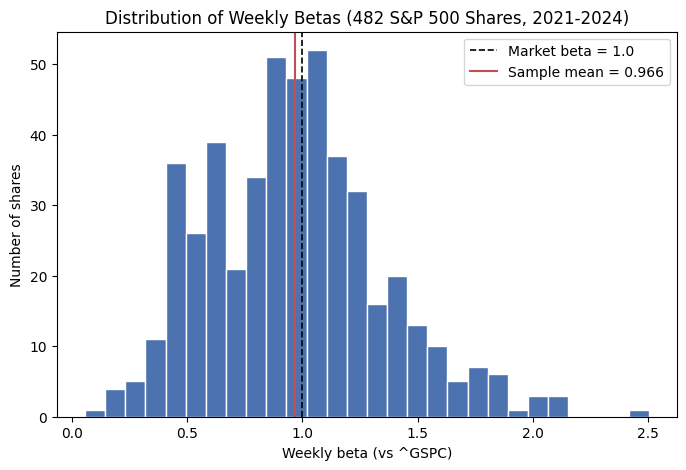

In [22]:
# Figure 1: Distribution of weekly betas across the validated shares
beta = risk_return_df['Weekly_Beta']

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(beta, bins=28, color='#4C72B0', edgecolor='white')

# Reference lines: market beta (1.0) and the sample mean
ax.axvline(1.0, color='black', linestyle='--', linewidth=1.2, label='Market beta = 1.0')
ax.axvline(beta.mean(), color='#C44E52', linestyle='-', linewidth=1.5,
           label=f'Sample mean = {beta.mean():.3f}')

ax.set_title('Distribution of Weekly Betas (482 S&P 500 Shares, 2021-2024)')
ax.set_xlabel('Weekly beta (vs ^GSPC)')
ax.set_ylabel('Number of shares')
ax.legend()

plt.savefig('fig1_beta_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

Risk return ptofile


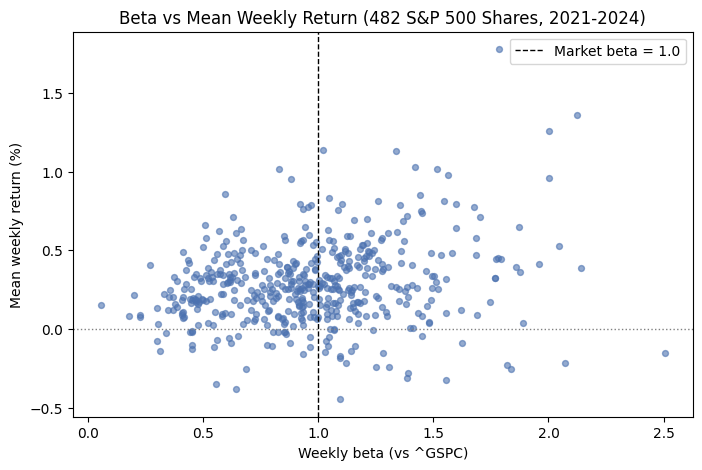

In [23]:
# Figure 2: Risk-return profile (beta vs mean weekly return)
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(risk_return_df['Weekly_Beta'],
           risk_return_df['Mean_Weekly_Return'] * 100,   # convert to % per week
           s=18, alpha=0.6, color='#4C72B0')

# Reference lines at market beta and zero return
ax.axvline(1.0, color='black', linestyle='--', linewidth=1, label='Market beta = 1.0')
ax.axhline(0, color='grey', linestyle=':', linewidth=1)

ax.set_title('Beta vs Mean Weekly Return (482 S&P 500 Shares, 2021-2024)')
ax.set_xlabel('Weekly beta (vs ^GSPC)')
ax.set_ylabel('Mean weekly return (%)')
ax.legend()

plt.savefig('fig2_beta_vs_return.png', dpi=300, bbox_inches='tight')
plt.show()